<a href="https://colab.research.google.com/github/fathazn/FORUM_DL/blob/main/forum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**SET UP**

In [115]:
# Import
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [116]:
# load dataset
transform = transforms.ToTensor()

full_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [117]:
# train dataset
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(full_dataset,[train_size, val_size])

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

48000
12000
10000


In [118]:
# dataloader
batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

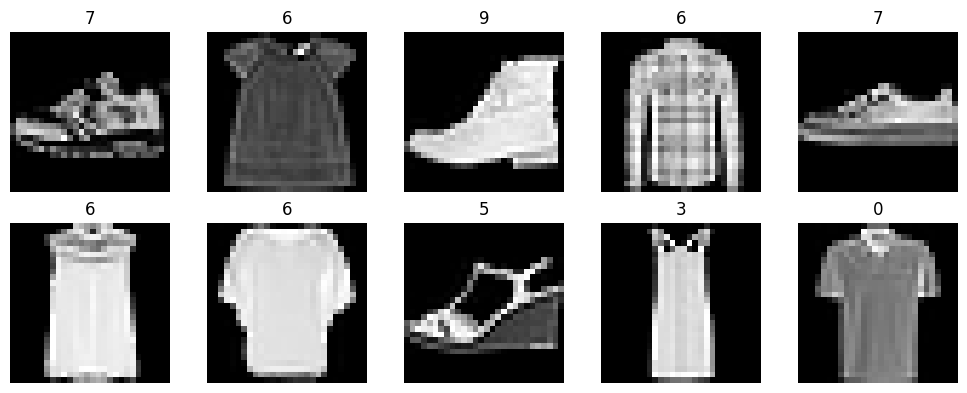

In [119]:
# visualisasi
images, labels = next(iter(train_loader))

plt.figure(figsize=(10,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(labels[i].item())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [120]:
class_names = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

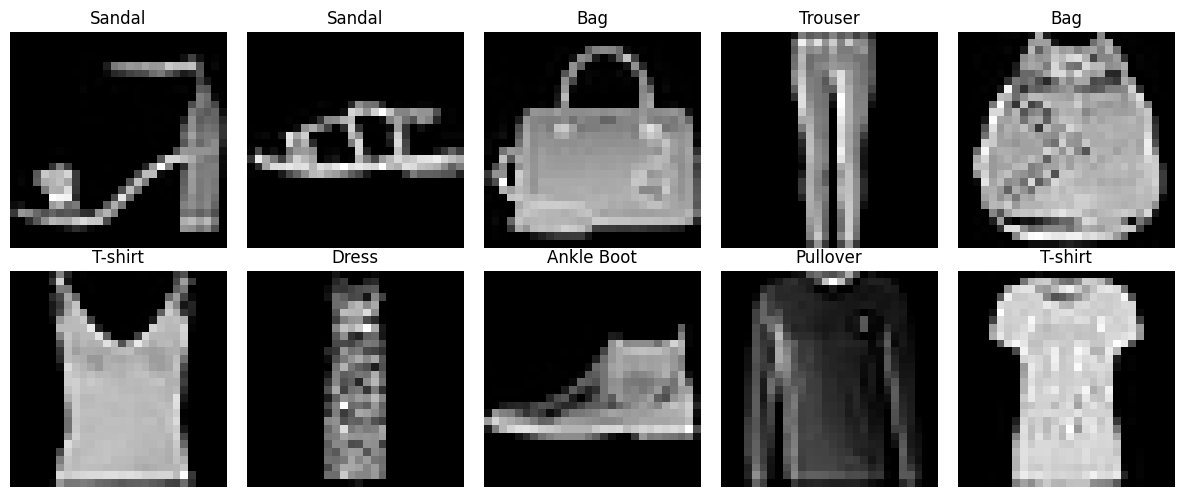

In [121]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Vanilla Autoencoder**

In [122]:
# buat model ae
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        x_hat = x_hat.view(-1, 1, 28, 28)

        return x_hat

In [123]:
# inisialisasi model
latent_dim = 64

ae = Autoencoder(latent_dim=latent_dim).to(device)

print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [124]:
criterion = nn.MSELoss()

optimizer = optim.Adam(ae.parameters(), lr=1e-3)

In [125]:
def train_autoencoder(model, train_loader, optimizer, criterion):
    model.train()
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)
        outputs = model(images)
        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(train_loader)

In [126]:
def validate_autoencoder(model,val_loader,criterion):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            outputs = model(images)
            loss = criterion(outputs, images)
            total_loss += loss.item()

    return total_loss / len(val_loader)

In [127]:
num_epochs = 20

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    train_loss = train_autoencoder(ae, train_loader, optimizer, criterion)
    val_loss = validate_autoencoder(ae, val_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

Epoch 1/20 | Train Loss: 0.04134 | Val Loss: 0.02405
Epoch 2/20 | Train Loss: 0.02182 | Val Loss: 0.02019
Epoch 3/20 | Train Loss: 0.01889 | Val Loss: 0.01811
Epoch 4/20 | Train Loss: 0.01720 | Val Loss: 0.01657
Epoch 5/20 | Train Loss: 0.01592 | Val Loss: 0.01559
Epoch 6/20 | Train Loss: 0.01498 | Val Loss: 0.01482
Epoch 7/20 | Train Loss: 0.01423 | Val Loss: 0.01421
Epoch 8/20 | Train Loss: 0.01363 | Val Loss: 0.01352
Epoch 9/20 | Train Loss: 0.01306 | Val Loss: 0.01301
Epoch 10/20 | Train Loss: 0.01262 | Val Loss: 0.01258
Epoch 11/20 | Train Loss: 0.01226 | Val Loss: 0.01229
Epoch 12/20 | Train Loss: 0.01192 | Val Loss: 0.01197
Epoch 13/20 | Train Loss: 0.01163 | Val Loss: 0.01177
Epoch 14/20 | Train Loss: 0.01136 | Val Loss: 0.01152
Epoch 15/20 | Train Loss: 0.01110 | Val Loss: 0.01148
Epoch 16/20 | Train Loss: 0.01085 | Val Loss: 0.01092
Epoch 17/20 | Train Loss: 0.01064 | Val Loss: 0.01081
Epoch 18/20 | Train Loss: 0.01043 | Val Loss: 0.01061
Epoch 19/20 | Train Loss: 0.01025 | V

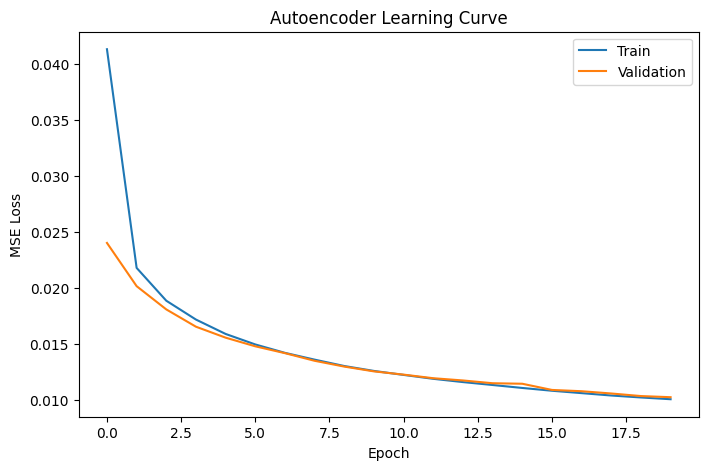

In [128]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Learning Curve")
plt.legend()
plt.show()

In [129]:
ae.eval()
images, _ = next(iter(test_loader))
images = images.to(device)
with torch.no_grad():
    reconstructed = ae(images)

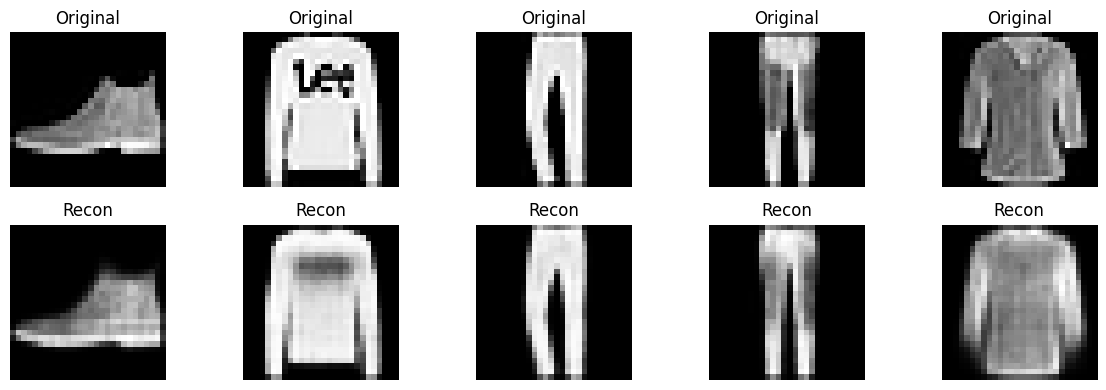

In [130]:
plt.figure(figsize=(12,4))

for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("Original")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("Recon")

plt.tight_layout()
plt.show()

In [131]:
torch.save(ae.state_dict(), "vanilla_autoencoder.pth")

print("Model saved!")

Model saved!


**Sparse Autoencoder**

In [132]:
class SparseAutoencoder(nn.Module)
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        reconstruction = reconstruction.view(-1, 1, 28, 28)

        return reconstruction, latent

In [133]:
sae = SparseAutoencoder(latent_dim=64).to(device)

print(sae)

SparseAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [134]:
criterion = nn.MSELoss()

optimizer_sae = optim.Adam(sae.parameters(),lr=1e-3)

In [135]:
def sparsity_penalty(latent):
    return torch.mean(torch.abs(latent))

In [136]:
def train_sparse_autoencoder(model, dataloader, optimizer, beta=1e-3):
    model.train()
    total_loss = 0

    for images, _ in dataloader:
        images = images.to(device)
        outputs, latent = model(images)
        reconstruction_loss = criterion(outputs, images)
        sparse_loss = sparsity_penalty(latent)

        loss = (reconstruction_loss + beta * sparse_loss)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(dataloader)

In [137]:
def validate_sparse_autoencoder(model, dataloader, beta=1e-3):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(device)
            outputs, latent = model(images)
            reconstruction_loss = criterion(outputs, images)
            sparse_loss = sparsity_penalty(latent)

            loss = (reconstruction_loss + beta * sparse_loss)

            total_loss += loss.item()

    return total_loss / len(dataloader)

In [138]:
epochs = 20

sae_train_losses = []
sae_val_losses = []

for epoch in range(epochs):

    train_loss = train_sparse_autoencoder(sae, train_loader, optimizer_sae)

    val_loss = validate_sparse_autoencoder(sae, val_loader)

    sae_train_losses.append(train_loss)
    sae_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train: {train_loss:.5f} "
        f"Val: {val_loss:.5f}"
    )

Epoch [1/20] Train: 0.04162 Val: 0.02377
Epoch [2/20] Train: 0.02128 Val: 0.01966
Epoch [3/20] Train: 0.01838 Val: 0.01755
Epoch [4/20] Train: 0.01665 Val: 0.01628
Epoch [5/20] Train: 0.01561 Val: 0.01527
Epoch [6/20] Train: 0.01477 Val: 0.01452
Epoch [7/20] Train: 0.01403 Val: 0.01385
Epoch [8/20] Train: 0.01342 Val: 0.01333
Epoch [9/20] Train: 0.01291 Val: 0.01287
Epoch [10/20] Train: 0.01246 Val: 0.01254
Epoch [11/20] Train: 0.01207 Val: 0.01206
Epoch [12/20] Train: 0.01172 Val: 0.01181
Epoch [13/20] Train: 0.01140 Val: 0.01143
Epoch [14/20] Train: 0.01112 Val: 0.01134
Epoch [15/20] Train: 0.01090 Val: 0.01093
Epoch [16/20] Train: 0.01066 Val: 0.01069
Epoch [17/20] Train: 0.01043 Val: 0.01057
Epoch [18/20] Train: 0.01022 Val: 0.01045
Epoch [19/20] Train: 0.01007 Val: 0.01017
Epoch [20/20] Train: 0.00988 Val: 0.01009


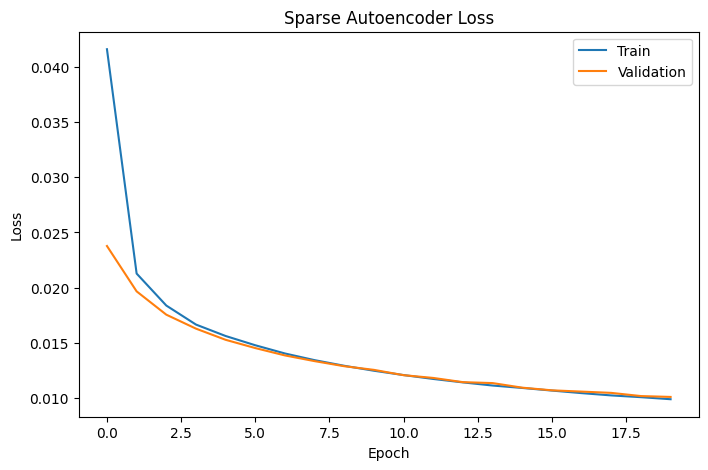

In [139]:
plt.figure(figsize=(8,5))
plt.plot(sae_train_losses,label="Train")
plt.plot(sae_val_losses,label="Validation")
plt.title("Sparse Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [140]:
sae.eval()

images, _ = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
  reconstructed, latent = sae(images)

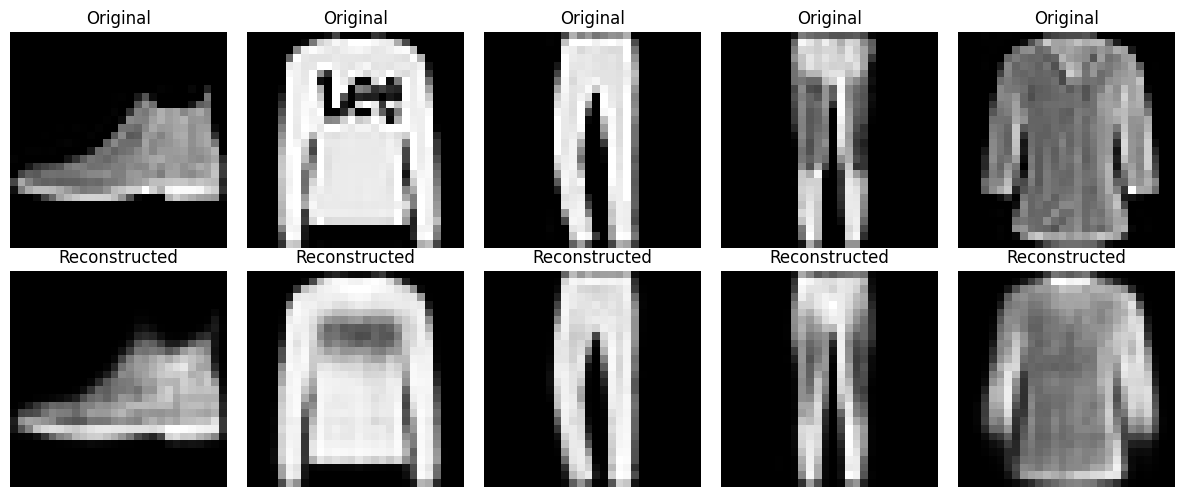

In [141]:
plt.figure(figsize=(12,5))

for i in range(5):

    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

**VAE**

In [142]:
class VAE(nn.Module):

    def __init__(self, latent_dim=64):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(128,latent_dim)

        self.fc_logvar = nn.Linear(128,latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decoder(z)
        reconstruction = reconstruction.view(-1, 1, 28, 28)

        return (reconstruction, mu, logvar)

In [143]:
latent_dim = 64

vae = VAE(latent_dim=latent_dim).to(device)

print(vae)

optimizer_vae = optim.Adam(vae.parameters(),lr=1e-3)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [144]:
def vae_loss(reconstruction, original, mu, logvar):
    reconstruction_loss = nn.functional.mse_loss(reconstruction, original, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return reconstruction_loss + kl_loss

In [145]:
def train_va(model, dataloader,optimizer):
    model.train()
    total_loss = 0
    for images, _ in dataloader:
        images = images.to(device)
        optimizer.zero_grad()
        reconstruction, mu, logvar = model(images)
        loss = vae_loss(reconstruction, images, mu, logvar)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

In [146]:
def validate_vae(model, dataloader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(device)
            reconstruction, mu, logvar = model(images)
            loss = vae_loss(reconstruction, images, mu, logvar)
            total_loss += loss.item()
    return total_loss / len(dataloader.dataset)

In [147]:
epoch = 20

vae_train_losses = []
vae_val_losses = []

for epoch in range(epoch):
    train_loss = train_va(vae, train_loader, optimizer_vae)
    val_loss = validate_vae(vae, val_loader)
    vae_train_losses.append(train_loss)
    vae_val_losses.append(val_loss)
    print(f"Epoch [{epoch+1}/{epoch}] Train: {train_loss:.5f} Val: {val_loss:.5f}")

Epoch [1/0] Train: 6287.69401 Val: 38.70137
Epoch [2/1] Train: 4394.37785 Val: 31.48086
Epoch [3/2] Train: 3810.36014 Val: 28.74145
Epoch [4/3] Train: 3544.68980 Val: 27.05192
Epoch [5/4] Train: 3404.05612 Val: 26.46367
Epoch [6/5] Train: 3330.84617 Val: 25.89938
Epoch [7/6] Train: 3282.72266 Val: 25.60814
Epoch [8/7] Train: 3243.78194 Val: 25.36007
Epoch [9/8] Train: 3214.22802 Val: 25.19790
Epoch [10/9] Train: 3196.32928 Val: 25.08860
Epoch [11/10] Train: 3175.34651 Val: 24.90601
Epoch [12/11] Train: 3156.13149 Val: 24.79044
Epoch [13/12] Train: 3145.79117 Val: 24.69967
Epoch [14/13] Train: 3132.17472 Val: 24.55303
Epoch [15/14] Train: 3122.22242 Val: 24.60176
Epoch [16/15] Train: 3112.91656 Val: 24.62463
Epoch [17/16] Train: 3101.41274 Val: 24.40772
Epoch [18/17] Train: 3092.44226 Val: 24.28603
Epoch [19/18] Train: 3078.40272 Val: 24.27307
Epoch [20/19] Train: 3074.01776 Val: 24.13189


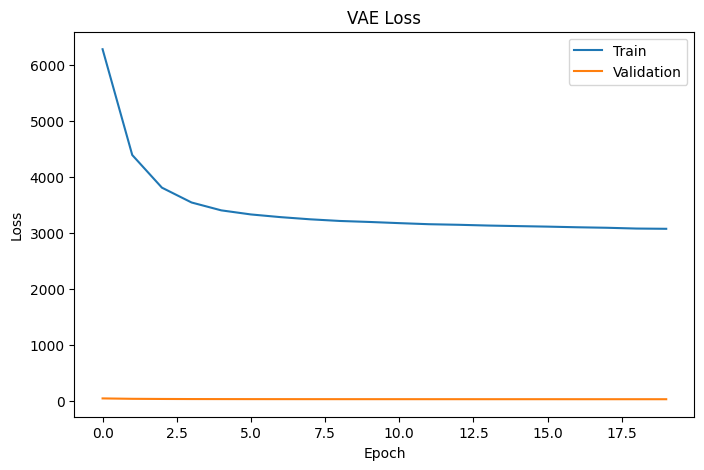

In [148]:
plt.figure(figsize=(8,5))
plt.plot(vae_train_losses,label="Train")
plt.plot(vae_val_losses,label="Validation")
plt.title("VAE Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [149]:
vae.eval()
images, _ = next(iter(test_loader))
images = images.to(device)
with torch.no_grad():
    reconstruction, mu, logvar = vae(images)

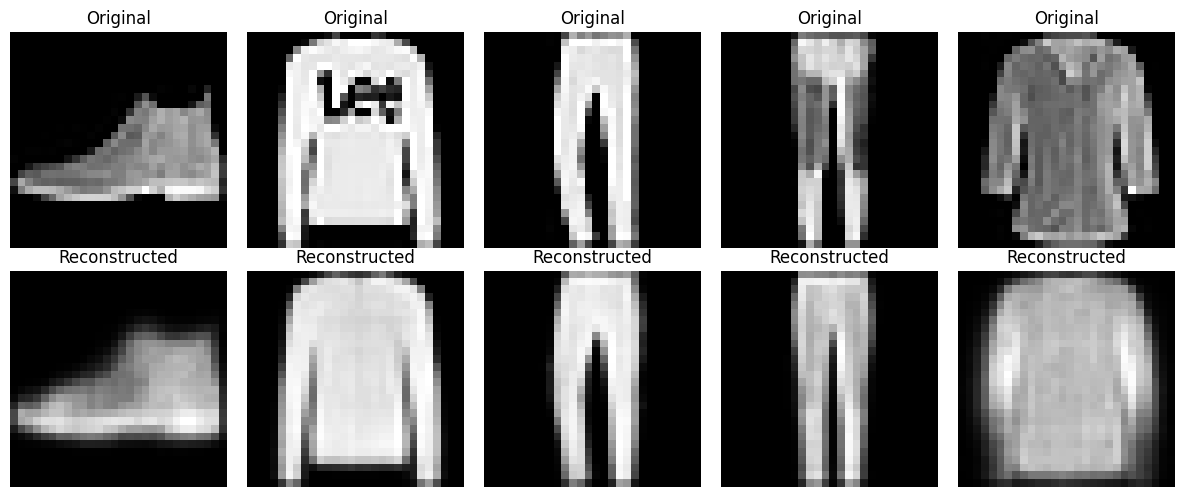

In [150]:
plt.figure(figsize=(12,5))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstruction[i].cpu().squeeze(), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")
plt.tight_layout()
plt.show()

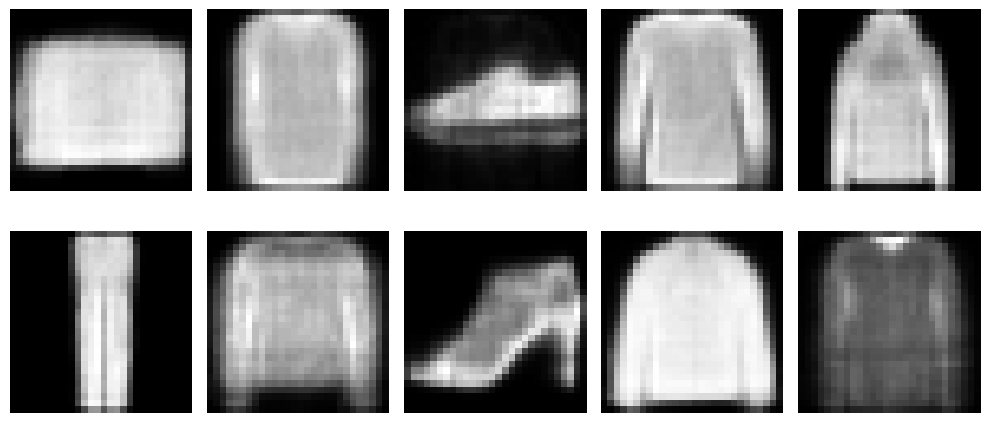

In [151]:
vae.eval()

with torch.no_grad():
  z = torch.randn(100, latent_dim).to(device)
  generated_images = vae.decoder(z)
  generated_images = generated_images.view(-1, 1, 28, 28)

plt.figure(figsize=(10,5))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(generated_images[i].cpu().squeeze(), cmap="gray")
  plt.axis("off")

plt.tight_layout()
plt.show()

**GAN**

In [152]:
latent_dim = 100
lr = 0.0002
epoch = 25

In [153]:
class Generator(nn.Module):
  def __init__(self):
    super(Generator, self).__init__()
    self.model = nn.Sequential(
        nn.Linear(latent_dim, 256),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Linear(256, 512),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Linear(512, 1024),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Linear(1024, 784),
        nn.Tanh()
    )
  def forward(self, z):
    img = self.model(z)
    img = img.view(img.size(0), 1, 28, 28)
    return img

class Discriminator(nn.Module):
  def __init__(self):
    super(Discriminator, self).__init__()
    self.model = nn.Sequential(
        nn.Linear(784, 1024),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Dropout(0.3),
        nn.Linear(1024, 512),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Dropout(0.3),
        nn.Linear(512, 256),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Dropout(0.3),
        nn.Linear(256, 1),
        nn.Sigmoid()
    )
  def forward(self, img):
      img_flat = img.view(img.size(0), -1)
      validity = self.model(img_flat)
      return validity

In [154]:
generator = Generator().to(device)
discriminator = Discriminator().to(device)
print(generator)
print(discriminator)

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2, inplace=True)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=True)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, 

In [155]:
criterion = nn.BCELoss()

optimizer_g = optim.Adam(generator.parameters(), lr=lr)
optimizer_d = optim.Adam(discriminator.parameters(), lr=lr)

In [156]:
g_losses = []
d_losses = []

for e in range(epochs):
  g_epoch_loss = 0
  d_epoch_loss = 0
  for i, (images, _) in enumerate(train_loader):
    images = images.to(device)
    batch_size = images.size(0)

    real_labels = torch.ones(batch_size, 1).to(device)
    fake_labels = torch.zeros(batch_size, 1).to(device)

    optimizer_g.zero_grad()
    z = torch.randn(batch_size, latent_dim).to(device)
    generated_images = generator(z)
    loss_g = criterion(discriminator(generated_images), real_labels)
    loss_g.backward()
    optimizer_g.step()

    optimizer_d.zero_grad()
    real_loss = criterion(discriminator(images), real_labels)
    fake_loss = criterion(discriminator(generated_images.detach()), fake_labels)
    loss_d = (real_loss + fake_loss) / 2
    loss_d.backward()
    optimizer_d.step()

    g_epoch_loss += loss_g.item()
    d_epoch_loss += loss_d.item()
  g_losses.append(g_epoch_loss / len(train_loader))
  d_losses.append(d_epoch_loss / len(train_loader))
  print(f"Epoch [{e+1}/{epochs}] G Loss: {g_epoch_loss/len(train_loader):.4f} D Loss: {d_epoch_loss/len(train_loader):.4f}")

Epoch [1/20] G Loss: 1.6236 D Loss: 0.5306
Epoch [2/20] G Loss: 1.2194 D Loss: 0.5996
Epoch [3/20] G Loss: 1.2626 D Loss: 0.4713
Epoch [4/20] G Loss: 1.2187 D Loss: 0.4970
Epoch [5/20] G Loss: 1.2794 D Loss: 0.5333
Epoch [6/20] G Loss: 1.3010 D Loss: 0.4758
Epoch [7/20] G Loss: 1.3261 D Loss: 0.4909
Epoch [8/20] G Loss: 1.3627 D Loss: 0.4622
Epoch [9/20] G Loss: 1.2380 D Loss: 0.4782
Epoch [10/20] G Loss: 1.4638 D Loss: 0.4385
Epoch [11/20] G Loss: 1.4422 D Loss: 0.4496
Epoch [12/20] G Loss: 1.7840 D Loss: 0.4486
Epoch [13/20] G Loss: 1.5143 D Loss: 0.4326
Epoch [14/20] G Loss: 1.6175 D Loss: 0.4191
Epoch [15/20] G Loss: 1.6419 D Loss: 0.3707
Epoch [16/20] G Loss: 1.4963 D Loss: 0.4688
Epoch [17/20] G Loss: 1.4034 D Loss: 0.4591
Epoch [18/20] G Loss: 1.4219 D Loss: 0.4397
Epoch [19/20] G Loss: 1.4826 D Loss: 0.4455
Epoch [20/20] G Loss: 1.4456 D Loss: 0.4552


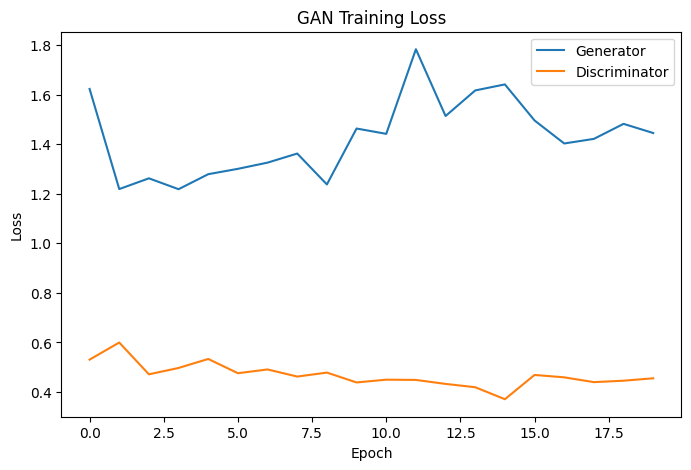

In [157]:
plt.figure(figsize=(8,5))
plt.plot(g_losses, label="Generator")
plt.plot(d_losses, label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.show()

In [158]:
generator.eval()
with torch.no_grad():
    noise = torch.randn(16,latent_dim).to(device)
    generated_images = generator(noise)

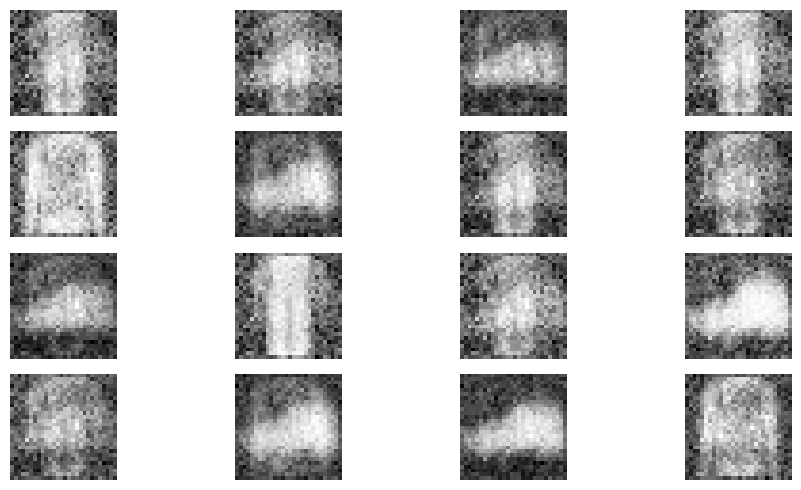

In [159]:
plt.figure(figsize=(10,5))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated_images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [160]:
torch.save(generator.state_dict(),"gan_generator.pth")
torch.save(discriminator.state_dict(), "gan_discriminator.pth")
print("GAN saved!")

GAN saved!


**DCGAN**

In [161]:
latent_dim = 100
lr = 0.0002
epochs = 20
image_size = 28

In [162]:
class DCGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # Input: (batch_size, 100, 1, 1)
            nn.ConvTranspose2d(100, 256, kernel_size=7, stride=1, padding=0),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # State: (batch_size, 256, 7, 7)
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # State: (batch_size, 128, 14, 14)
            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1), # Changed padding from 3 to 1 to yield 28x28
            nn.Tanh()
            # Output: (batch_size, 1, 28, 28)
        )

    def forward(self, z):
        return self.model(z)

In [163]:
class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # Input: (batch_size, 1, 28, 28)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (batch_size, 64, 14, 14)
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (batch_size, 128, 7, 7)
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

In [164]:
dc_generator = DCGenerator().to(device)

dc_discriminator = DCDiscriminator().to(device)

print(dc_generator)
print(dc_discriminator)

DCGenerator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)
DCDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten(start_dim=1, end_dim=-1)
    (

In [165]:
# Re-instantiate the updated models on the device
dc_generator = DCGenerator().to(device)
dc_discriminator = DCDiscriminator().to(device)

# Set loss function
criterion = nn.BCELoss()

# Configure Adam optimizers with the updated model parameters
optimizer_G = optim.Adam(dc_generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = optim.Adam(dc_discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

print("Models and optimizers successfully re-initialized with matching 28x28 shapes!")

Models and optimizers successfully re-initialized with matching 28x28 shapes!


In [166]:
dc_g_losses = []
dc_d_losses = []

for epoch in range(epochs):

    g_epoch_loss = 0
    d_epoch_loss = 0

    for real_imgs, _ in train_loader:
        real_imgs = real_imgs.to(device)
        batch_size = real_imgs.size(0)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        optimizer_D.zero_grad()

        real_output = dc_discriminator(real_imgs)
        d_real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, latent_dim, 1, 1).to(device)

        fake_imgs = dc_generator(noise)
        fake_output = dc_discriminator(fake_imgs.detach())

        d_fake_loss = criterion(fake_output, fake_labels)
        d_loss = (d_real_loss + d_fake_loss)
        d_loss.backward()
        optimizer_D.step()

        optimizer_G.zero_grad()

        noise = torch.randn(batch_size, latent_dim, 1, 1).to(device)

        generated_imgs = dc_generator(noise)

        output = dc_discriminator(generated_imgs)

        g_loss = criterion(output, real_labels)

        g_loss.backward()

        optimizer_G.step()

        g_epoch_loss += g_loss.item()
        d_epoch_loss += d_loss.item()

    dc_g_losses.append(g_epoch_loss / len(train_loader))

    dc_d_losses.append(d_epoch_loss / len(train_loader))

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"D Loss: {dc_d_losses[-1]:.4f} "
        f"G Loss: {dc_g_losses[-1]:.4f} "
    )

Epoch [1/20] D Loss: 0.5208 G Loss: 2.2317 
Epoch [2/20] D Loss: 0.2946 G Loss: 2.7164 
Epoch [3/20] D Loss: 0.2222 G Loss: 3.2346 
Epoch [4/20] D Loss: 0.1595 G Loss: 3.6928 
Epoch [5/20] D Loss: 0.0995 G Loss: 4.5619 
Epoch [6/20] D Loss: 0.1336 G Loss: 4.4235 
Epoch [7/20] D Loss: 0.1029 G Loss: 4.6664 
Epoch [8/20] D Loss: 0.1164 G Loss: 5.1769 
Epoch [9/20] D Loss: 0.0719 G Loss: 4.8046 
Epoch [10/20] D Loss: 0.1628 G Loss: 4.4364 
Epoch [11/20] D Loss: 0.0732 G Loss: 5.0842 
Epoch [12/20] D Loss: 0.0992 G Loss: 5.3772 
Epoch [13/20] D Loss: 0.1228 G Loss: 4.8189 
Epoch [14/20] D Loss: 0.0402 G Loss: 5.3161 
Epoch [15/20] D Loss: 0.1142 G Loss: 5.1992 
Epoch [16/20] D Loss: 0.0453 G Loss: 5.5430 
Epoch [17/20] D Loss: 0.0748 G Loss: 5.4257 
Epoch [18/20] D Loss: 0.1281 G Loss: 4.9951 
Epoch [19/20] D Loss: 0.1675 G Loss: 5.8653 
Epoch [20/20] D Loss: 0.0919 G Loss: 4.7642 


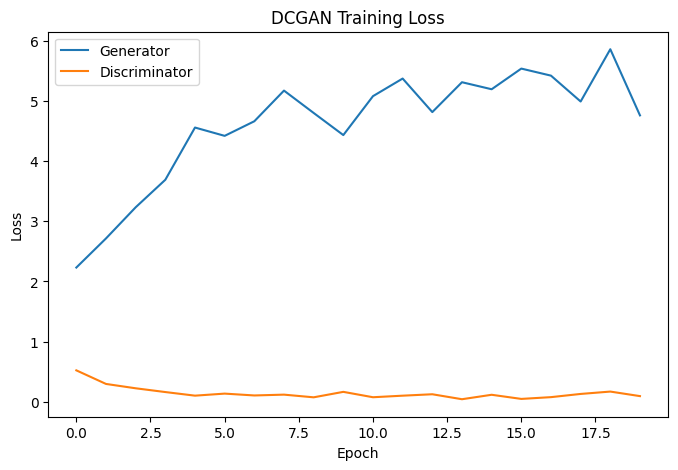

In [167]:
plt.figure(figsize=(8,5))
plt.plot(dc_g_losses, label="Generator")
plt.plot(dc_d_losses, label="Discriminator")
plt.title("DCGAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [168]:
dc_generator.eval()

with torch.no_grad():
    noise = torch.randn(16, latent_dim, 1, 1).to(device)
    generated_imgs = dc_generator(noise)

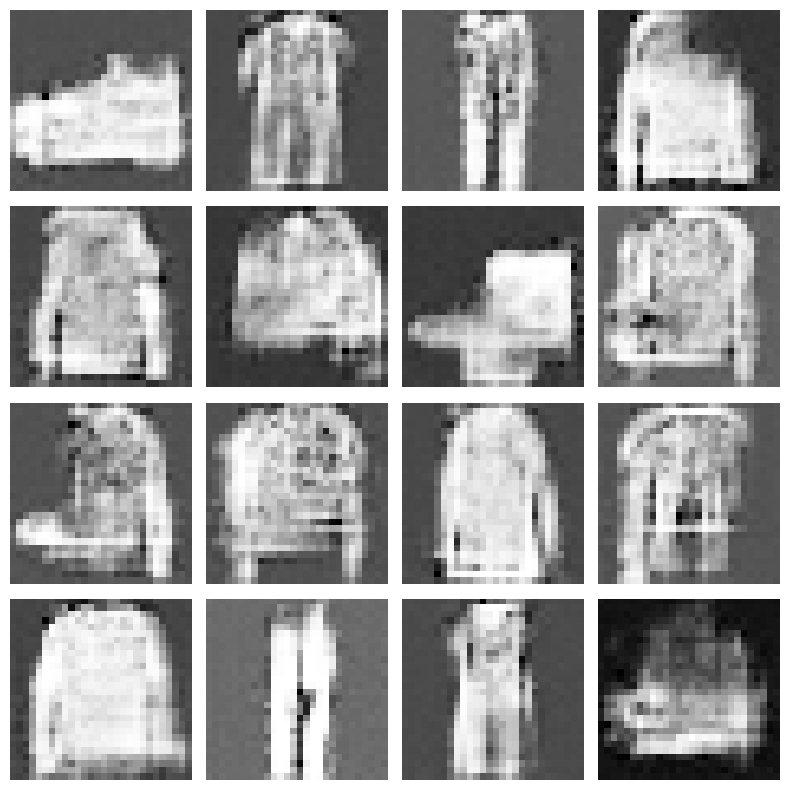

In [169]:
plt.figure(figsize=(8,8))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated_imgs[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [170]:
torch.save(
    dc_generator.state_dict(),
    "dcgan_generator.pth"
)

torch.save(
    dc_discriminator.state_dict(),
    "dcgan_discriminator.pth"
)

print("DCGAN Saved!")

DCGAN Saved!


**bold text**

In [171]:
IMAGE_SIZE = 28
CHANNELS = 1

BATCH_SIZE = 128

TIMESTEPS = 100

EPOCHS = 20

LR = 1e-3

In [172]:
beta_start = 1e-4
beta_end = 0.02

betas = torch.linspace(beta_start, beta_end, TIMESTEPS).to(device)

alphas = 1. - betas

alpha_bars = torch.cumprod(alphas, dim=0)

In [173]:
def forward_diffusion_sample(x0, t):

    noise = torch.randn_like(x0)
    alpha_bar_t = alpha_bars[t]

    sqrt_alpha_bar = torch.sqrt(alpha_bar_t).view(-1,1,1,1)
    sqrt_one_minus_alpha_bar = torch.sqrt(1 - alpha_bar_t).view(-1,1,1,1)

    noisy_image = (sqrt_alpha_bar * x0 + sqrt_one_minus_alpha_bar * noise)

    return noisy_image, noise

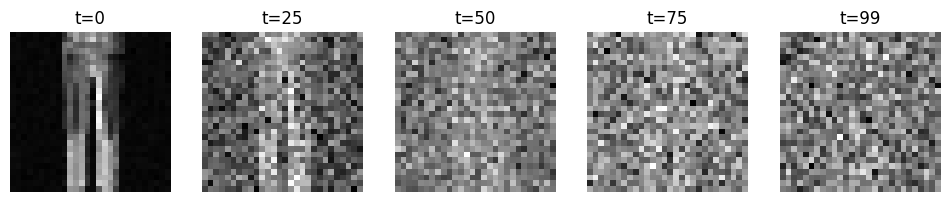

In [174]:
sample, _ = next(iter(train_loader))
sample = sample[:1].to(device)

# Changed steps to remain within [0, TIMESTEPS-1] (0 to 99)
steps = [0, 25, 50, 75, 99]

plt.figure(figsize=(12,3))

for i, t in enumerate(steps):
    t_tensor = torch.tensor([t]).to(device)
    noisy, _ = forward_diffusion_sample(sample, t_tensor)

    plt.subplot(1,5,i+1)
    plt.imshow(noisy[0].cpu().squeeze(), cmap="gray")
    plt.title(f"t={t}")
    plt.axis("off")

plt.show()

In [175]:
class SimpleDDPM(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, 3, padding=1)
        )

    def forward(self, x, t):
        return self.net(x)

In [176]:
ddpm = SimpleDDPM().to(device)

optimizer_ddpm = optim.Adam(ddpm.parameters(), lr=LR)

criterion = nn.MSELoss()


In [177]:
def train_ddpm_epoch():
    ddpm.train()
    total_loss = 0

    for images,_ in train_loader:
        images = images.to(device)

        t = torch.randint(0, TIMESTEPS, (images.shape[0],), device=device)

        noisy_images, noise = (forward_diffusion_sample(images, t))

        predicted_noise = ddpm(noisy_images, t)
        loss = criterion(predicted_noise, noise)

        optimizer_ddpm.zero_grad()
        loss.backward()
        optimizer_ddpm.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)

In [112]:
ddpm_losses = []

for epoch in range(EPOCHS):
    loss = train_ddpm_epoch()
    ddpm_losses.append(loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
        f" | Loss: {loss:.5f}"
    )

Epoch 1/20 | Loss: 0.13022
Epoch 2/20 | Loss: 0.12371
Epoch 3/20 | Loss: 0.11987
Epoch 4/20 | Loss: 0.11810
Epoch 5/20 | Loss: 0.11527
Epoch 6/20 | Loss: 0.11293
Epoch 7/20 | Loss: 0.11230
Epoch 8/20 | Loss: 0.11186
Epoch 9/20 | Loss: 0.11060
Epoch 10/20 | Loss: 0.10931
Epoch 11/20 | Loss: 0.10929
Epoch 12/20 | Loss: 0.10845
Epoch 13/20 | Loss: 0.10805
Epoch 14/20 | Loss: 0.10730
Epoch 15/20 | Loss: 0.10709
Epoch 16/20 | Loss: 0.10698
Epoch 17/20 | Loss: 0.10662
Epoch 18/20 | Loss: 0.10658
Epoch 19/20 | Loss: 0.10604
Epoch 20/20 | Loss: 0.10620


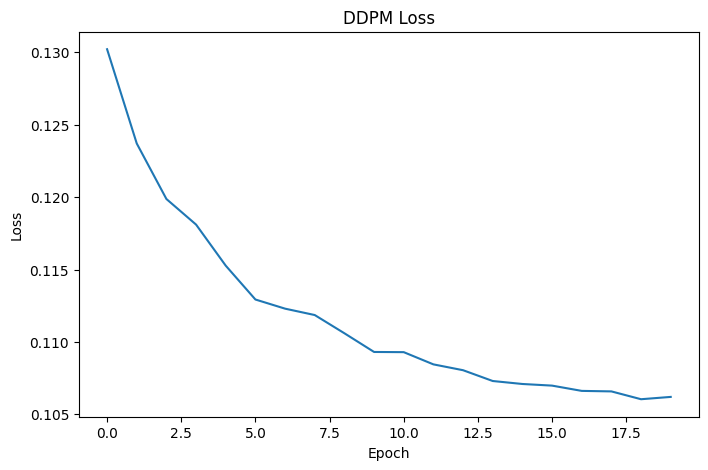

In [113]:
plt.figure(figsize=(8,5))
plt.plot(ddpm_losses)
plt.title("DDPM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()


In [114]:
@torch.no_grad()
def sample_ddpm(model, n=16):
    model.eval()
    x = torch.randn(n, 1, 28, 28).to(device)

    for t in reversed(range(TIMESTEPS)):
        predicted_noise = model(x, torch.tensor([t], device=device))

        x = x - (betas[t] * predicted_noise)

    return x

In [178]:
generated = sample_ddpm(ddpm, 16)

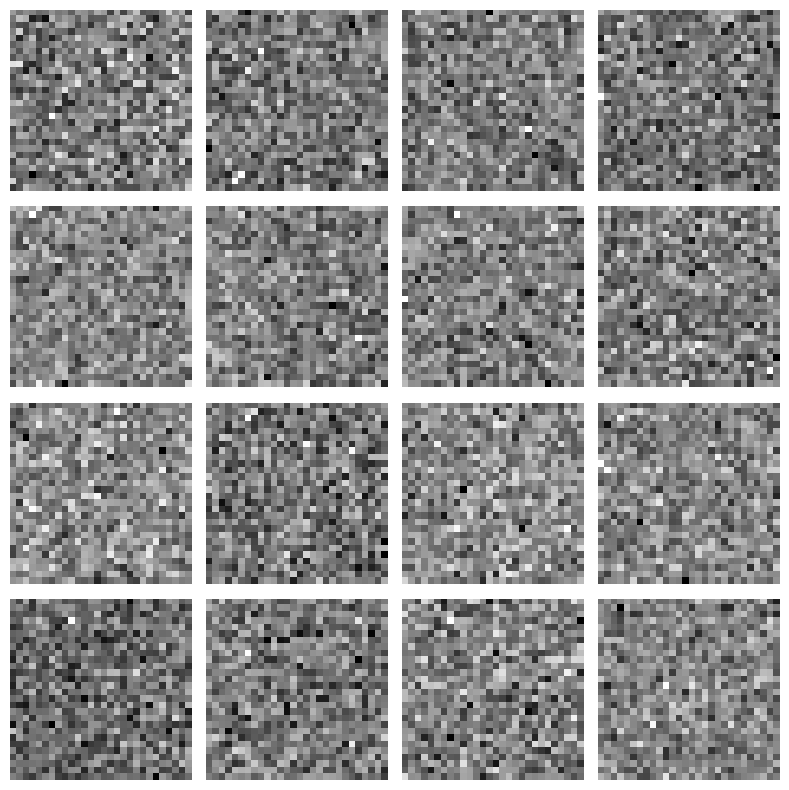

In [179]:
plt.figure(figsize=(8,8))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()

plt.show()

In [180]:
torch.save(ddpm.state_dict(), "ddpm_model.pth")

print("DDPM saved!")

DDPM saved!
